### so this whole notebook is about cross validation and the usage of evaluation metrics


### IMPORTING PACKAGES AND LOADING DATASET , IMPLEMENTING X AND Y BLAH BLAH

In [1]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn import datasets
from sklearn import svm

X, y = datasets.load_iris(return_X_y=True)
X.shape, y.shape

((150, 4), (150,))

### SPLITTING INTO TRAINING AND TESTING SETS

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=0)

X_train.shape, y_train.shape
X_test.shape, y_test.shape

# model training
# kernel and margin trade off implementing
clf = svm.SVC(kernel='linear', C=1).fit(X_train, y_train)
clf.score(X_test, y_test)

0.9666666666666667

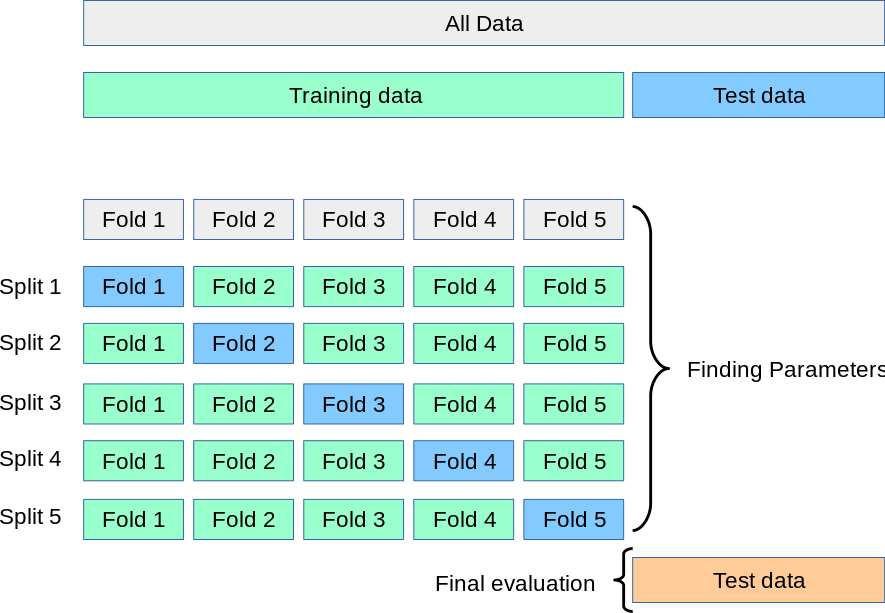

### model testing over the splitted 5 folds

In [ ]:


from sklearn.model_selection import cross_val_score
clf = svm.SVC(kernel='linear', C=1, random_state=42)
scores = cross_val_score(clf, X, y, cv=5)
scores

array([0.96666667, 1.        , 0.96666667, 0.96666667, 1.        ])

### overall performance result of the model

In [4]:
print("%0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

0.98 accuracy with a standard deviation of 0.02


### another method, we use Shufflesplit method to shuffle the dataset for train/test split methods


In [5]:
from sklearn.model_selection import ShuffleSplit
n_samples = X.shape[0]
cv = ShuffleSplit(n_splits=5, test_size=0.3, random_state=0)
cross_val_score(clf, X, y, cv=cv)

array([0.97777778, 0.97777778, 1.        , 0.95555556, 1.        ])

2-fold cross-validation on a dataset with 4 samples
KFold does not consider class labels

### to avoid imbalanced dataset , spread the dataset evenly , and keep the class proportion, we use stratifiewdkfold 

In [ ]:
from sklearn.model_selection import StratifiedKFold, KFold
import numpy as np
X = ["a", "b", "c", "d"]
kf = KFold(n_splits=2)
for train, test in kf.split(X):
    print("%s %s" % (train, test))

[2 3] [0 1]
[0 1] [2 3]


### iterating KFold multiple times

In [ ]:
import numpy as np
from sklearn.model_selection import RepeatedKFold
X = np.array([[1, 2], [3, 4], [1, 2], [3, 4]])
random_state = 12883823
rkf = RepeatedKFold(n_splits=2, n_repeats=2, random_state=random_state)
for train, test in rkf.split(X):
    print("%s %s" % (train, test))

[2 3] [0 1]
[0 1] [2 3]
[0 2] [1 3]
[1 3] [0 2]


### leave one and train the rest

In [ ]:
from sklearn.model_selection import LeaveOneOut

X = [1, 2, 3, 4]
loo = LeaveOneOut()
for train, test in loo.split(X):
    print("%s %s" % (train, test))

[1 2 3] [0]
[0 2 3] [1]
[0 1 3] [2]
[0 1 2] [3]


### leaving P number of the set and train the rest set

In [ ]:
from sklearn.model_selection import LeavePOut

X = np.ones(4)
lpo = LeavePOut(p=2)
for train, test in lpo.split(X):
    print("%s %s" % (train, test))

[2 3] [0 1]
[1 3] [0 2]
[1 2] [0 3]
[0 3] [1 2]
[0 2] [1 3]
[0 1] [2 3]


### using shuffle split, how many splits we want to use from the shuffled dataset , testing size(25% in this one)

In [ ]:
from sklearn.model_selection import ShuffleSplit
X = np.arange(10)
ss = ShuffleSplit(n_splits=5, test_size=0.25, random_state=0)
for train_index, test_index in ss.split(X):
    print("%s %s" % (train_index, test_index))

[9 1 6 7 3 0 5] [2 8 4]
[2 9 8 0 6 7 4] [3 5 1]
[4 5 1 0 6 9 7] [2 3 8]
[2 7 5 8 0 3 4] [6 1 9]
[4 1 0 6 8 9 3] [5 2 7]


### created a simple dataset with 50 rows and 1 columns with 45 "0"s and 5 "1"s

In [ ]:
X, y = np.ones((50, 1)), np.hstack(([0] * 45, [1] * 5))

### StratifiedKFold is initialized

In [ ]:
skf = StratifiedKFold(n_splits=3)

In [ ]:
for train, test in skf.split(X, y):
  print('train -  {}   |   test -  {}'.format(
        np.bincount(y[train]), np.bincount(y[test])))

train -  [30  3]   |   test -  [15  2]
train -  [30  3]   |   test -  [15  2]
train -  [30  4]   |   test -  [15  1]


In [ ]:
kf = KFold(n_splits=3)

### viewing the train test splittion of the kfold

In [ ]:
for train, test in kf.split(X, y):
    print('train -  {}   |   test -  {}'.format(
        np.bincount(y[train]), np.bincount(y[test])))

train -  [28  5]   |   test -  [17]
train -  [28  5]   |   test -  [17]
train -  [34]   |   test -  [11  5]


### now we learn the nature of Statified shuffled split
### 5 splits like before , 50% testing size

In [ ]:
import numpy as np
from sklearn.model_selection import StratifiedShuffleSplit
X = np.array([[1, 2], [3, 4], [1, 2], [3, 4], [1, 2], [3, 4]])
y = np.array([0, 0, 0, 1, 1, 1])
sss = StratifiedShuffleSplit(n_splits=5, test_size=0.5, random_state=0)
sss.get_n_splits()

5

In [ ]:
print(sss)

StratifiedShuffleSplit(n_splits=5, random_state=0, test_size=0.5,
            train_size=None)


In [ ]:
for i, (train_index, test_index) in enumerate(sss.split(X, y)):
    print(f"Fold {i}:")
    print(f"  Train: index={train_index}")
    print(f"  Test:  index={test_index}")

Fold 0:
  Train: index=[5 2 3]
  Test:  index=[4 1 0]
Fold 1:
  Train: index=[5 1 4]
  Test:  index=[0 2 3]
Fold 2:
  Train: index=[5 0 2]
  Test:  index=[4 3 1]
Fold 3:
  Train: index=[4 1 0]
  Test:  index=[2 3 5]
Fold 4:
  Train: index=[0 5 1]
  Test:  index=[3 4 2]


Evaluatinon Metric

### We import the functions needed to measure model performance.

* precision_score → How many predicted positives are correct?
* recall_score → How many real positives did we find?
* f1_score → Balance between precision and recall.

In [ ]:
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
# perfect precision, 50% recall
y_true = [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
y_pred = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
p = precision_score(y_true, y_pred)
r = recall_score(y_true, y_pred)
f = f1_score(y_true, y_pred)
print('Result: p=%.3f, r=%.3f, f=%.3f' % (p, r, f))

Result: p=0.500, r=1.000, f=0.667


### The model predicts all cases as Positive. Because of this:

* Precision = 50% → Half of the Positive predictions are correct.
* Recall = 100% → The model finds all real Positive cases.
* F1 Score = 66.7% → A combined score of Precision and Recall.


In [ ]:
# calculate the f1-measure
from sklearn.metrics import fbeta_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
# perfect precision, 50% recall
y_true = [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
y_pred = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
p = precision_score(y_true, y_pred)
r = recall_score(y_true, y_pred)
f = fbeta_score(y_true, y_pred, beta=1.0)
print('Result: p=%.3f, r=%.3f, f=%.3f' % (p, r, f))

Result: p=0.500, r=1.000, f=0.667


* precision_score() → calculates Precision
* recall_score() → calculates Recall
* fbeta_score(..., beta=1.0) → calculates F1 Score
* y_true → the real answers
* y_pred → the model’s predictions
* The model predicts all 10 cases as Positive.

### F0.5 gives more importance to Precision than Recall.

In [ ]:
# calculate the f0.5-measure
from sklearn.metrics import fbeta_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
# perfect precision, 50% recall
y_true = [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
y_pred = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
p = precision_score(y_true, y_pred)
r = recall_score(y_true, y_pred)
f = fbeta_score(y_true, y_pred, beta=0.5)
print('Result: p=%.3f, r=%.3f, f=%.3f' % (p, r, f))

Result: p=0.500, r=1.000, f=0.556


### F2 gives more importance to Recall than Precision.

In [ ]:
# calculate the f2-measure
from sklearn.metrics import fbeta_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
# perfect precision, 50% recall
y_true = [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
y_pred = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
p = precision_score(y_true, y_pred)
r = recall_score(y_true, y_pred)
f = fbeta_score(y_true, y_pred, beta=2.0)
print('Result: p=%.3f, r=%.3f, f=%.3f' % (p, r, f))

Result: p=0.500, r=1.000, f=0.833
